### A. Judul

Analisis Numerik: Regresi dan Pencarian Akar
Analisis Revenue dan Break-Even Point pada Lima Gerai Donat

Nama: Muhammad Haikal Ardiansyah  
Mata Kuliah: Analisis Numerik
Kelas: A083

### B. Import Library

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

- Membaca Dataset
##### 1. Persiapan Data

Dataset yang digunakan merupakan data laba/rugi harian dari lima gerai donat dengan strategi pemasaran yang berbeda. Data akan dibaca menggunakan pandas untuk selanjutnya dilakukan eksplorasi dan analisis.

In [23]:
df = pd.read_csv("sintesis_data_donat_harian.csv")

df.head()

,Tanggal,Gerai,Harga Jual (Rp),Jumlah Terjual (Unit),Pendapatan Kotor (Rp),Biaya Variabel (Rp),Fixed Cost Harian (Rp),Balance (Rp)
0,2026-01-01,Gerai A,25000,87,2175000,739500,1683333,-247833
1,2026-01-02,Gerai A,25000,81,2025000,688500,1683333,-346833
2,2026-01-03,Gerai A,25000,110,2750000,935000,1683333,131667
3,2026-01-04,Gerai A,25000,119,2975000,1011500,1683333,280167
4,2026-01-05,Gerai A,25000,94,2350000,799000,1683333,-132333


Melihat Struktur Data

In [24]:
print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data:")
print(df.dtypes)

Ukuran dataset: (450, 8)

Nama kolom:
['Tanggal', 'Gerai', 'Harga Jual (Rp)', 'Jumlah Terjual (Unit)', 'Pendapatan Kotor (Rp)', 'Biaya Variabel (Rp)', 'Fixed Cost Harian (Rp)', 'Balance (Rp)']

Tipe data:
Tanggal                   object
Gerai                     object
Harga Jual (Rp)            int64
Jumlah Terjual (Unit)      int64
Pendapatan Kotor (Rp)      int64
Biaya Variabel (Rp)        int64
Fixed Cost Harian (Rp)     int64
Balance (Rp)               int64
dtype: object


Interpretasi

Dataset terdiri dari 450 baris dan 8 kolom. Data mencakup informasi tanggal, gerai, harga jual, jumlah produk terjual, pendapatan kotor, biaya variabel, fixed cost harian, dan balance.

Mengecek Data

In [25]:
print("Jumlah missing value:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

Jumlah missing value:
Tanggal                   0
Gerai                     0
Harga Jual (Rp)           0
Jumlah Terjual (Unit)     0
Pendapatan Kotor (Rp)     0
Biaya Variabel (Rp)       0
Fixed Cost Harian (Rp)    0
Balance (Rp)              0
dtype: int64

Jumlah data duplikat: 0


In [26]:
df.describe()

,Harga Jual (Rp),Jumlah Terjual (Unit),Pendapatan Kotor (Rp),Biaya Variabel (Rp),Fixed Cost Harian (Rp),Balance (Rp)
count,450.000000,450.000000,4.500000e+02,4.500000e+02,4.500000e+02,4.500000e+02
mean,15800.000000,266.402222,3.342420e+06,1.427089e+06,1.523333e+06,3.919975e+05
std,6119.085481,160.911187,8.660617e+05,5.392152e+05,7.113147e+05,8.492523e+05
min,8000.000000,81.000000,2.025000e+06,6.885000e+05,7.333330e+05,-1.348266e+06
25%,11000.000000,127.250000,2.596250e+06,9.860000e+05,8.000000e+05,-2.364530e+05
50%,15000.000000,221.500000,3.262500e+06,1.327730e+06,1.683333e+06,3.131670e+05
75%,20000.000000,384.500000,4.015750e+06,1.866800e+06,1.733333e+06,1.132530e+06
max,25000.000000,710.000000,5.742000e+06,2.953600e+06,2.666666e+06,2.088400e+06


Interpretasi

Pengecekan dilakukan untuk memastikan tidak terdapat nilai yang hilang atau permasalahan data yang dapat mengganggu proses analisis. Statistik deskriptif digunakan untuk melihat karakteristik umum dari data numerik.

Melihat Lima Gerai

In [27]:
print(df["Gerai"].unique())
print("\nJumlah data setiap gerai:")
print(df["Gerai"].value_counts())

['Gerai A' 'Gerai B' 'Gerai C' 'Gerai D' 'Gerai E']

Jumlah data setiap gerai:
Gerai
Gerai A    90
Gerai B    90
Gerai C    90
Gerai D    90
Gerai E    90
Name: count, dtype: int64


- Plot Jumlah Penjualan vs Revenue
##### 2. Plot Jumlah Penjualan vs Revenue

Pada bagian ini akan dibuat scatter plot untuk melihat hubungan antara jumlah penjualan dan pendapatan kotor pada masing-masing gerai.

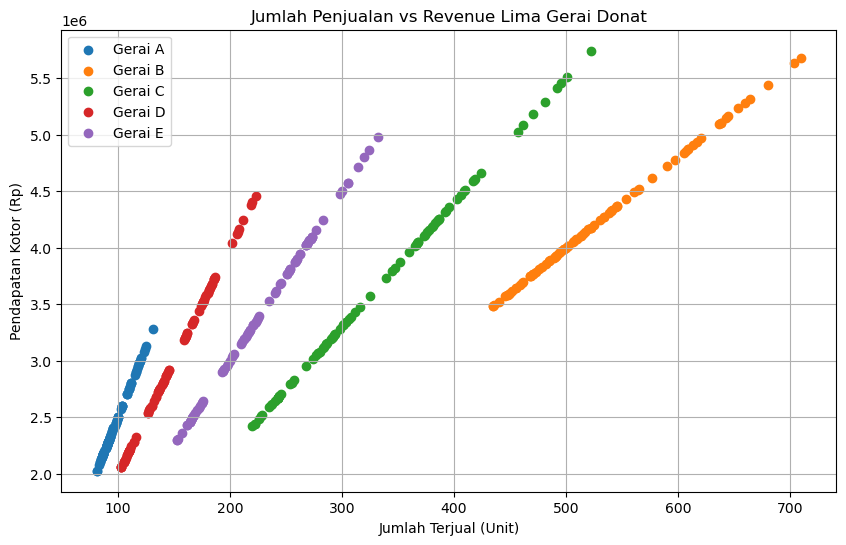

In [28]:
gerai_list = ["Gerai A", "Gerai B", "Gerai C", "Gerai D", "Gerai E"]

plt.figure(figsize=(10, 6))

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]
    
    plt.scatter(
        data["Jumlah Terjual (Unit)"],
        data["Pendapatan Kotor (Rp)"],
        label=gerai
    )

plt.xlabel("Jumlah Terjual (Unit)")
plt.ylabel("Pendapatan Kotor (Rp)")
plt.title("Jumlah Penjualan vs Revenue Lima Gerai Donat")
plt.legend()
plt.grid(True)
plt.show()

Interpretasi

Scatter plot menunjukkan hubungan antara volume penjualan dengan pendapatan kotor pada kelima gerai. Secara umum, semakin banyak unit donat yang terjual, semakin besar pendapatan yang diperoleh. Pola hubungan tersebut terlihat cenderung linear sehingga regresi linear dapat digunakan sebagai model awal.

- Membuat Regresi Linear
##### 3. Regresi Linear Revenue terhadap Volume Penjualan

Regresi digunakan untuk mengetahui bentuk hubungan antara jumlah donat yang terjual sebagai variabel independen (X) dan pendapatan kotor sebagai variabel dependen (Y).

Model regresi linear dinyatakan sebagai:

Y = aX + b

dengan:
- X = jumlah donat terjual
- Y = pendapatan kotor
- a = koefisien regresi
- b = intercept

In [29]:
hasil_regresi = {}

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]
    
    x = data["Jumlah Terjual (Unit)"].values
    y = data["Pendapatan Kotor (Rp)"].values
    
    a, b = np.polyfit(x, y, 1)
    
    hasil_regresi[gerai] = {
        "a": a,
        "b": b
    }
    
    print(f"{gerai}:")
    print(f"Revenue = {a:.2f}X + {b:.2f}")
    print()

Gerai A:
Revenue = 25000.00X + 0.00

Gerai B:
Revenue = 8000.00X + 0.00

Gerai C:
Revenue = 11000.00X + 0.00

Gerai D:
Revenue = 20000.00X + -0.00

Gerai E:
Revenue = 15000.00X + 0.00



- Menghitung R²

##### 4. Evaluasi Model Regresi

Koefisien determinasi (R²) digunakan untuk melihat seberapa besar variasi revenue dapat dijelaskan oleh jumlah penjualan menggunakan model regresi.

In [30]:
hasil_evaluasi = []

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]
    
    x = data["Jumlah Terjual (Unit)"].values
    y = data["Pendapatan Kotor (Rp)"].values
    
    a, b = np.polyfit(x, y, 1)
    y_pred = a * x + b
    
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    
    r2 = 1 - (ss_res / ss_tot)
    
    hasil_evaluasi.append([gerai, a, b, r2])

hasil_evaluasi_df = pd.DataFrame(
    hasil_evaluasi,
    columns=["Gerai", "Koefisien a", "Intercept b", "R2"]
)

hasil_evaluasi_df

,Gerai,Koefisien a,Intercept b,R2
0,Gerai A,25000.0,0.000000e+00,1.0
1,Gerai B,8000.0,3.926801e-10,1.0
2,Gerai C,11000.0,0.000000e+00,1.0
3,Gerai D,20000.0,-9.817002e-10,1.0
4,Gerai E,15000.0,1.963400e-10,1.0


Interpretasi

Nilai R² yang mendekati 1 menunjukkan bahwa model regresi linear memiliki kecocokan yang sangat tinggi terhadap data revenue. Oleh karena itu, regresi linear digunakan untuk merepresentasikan hubungan volume penjualan dan revenue pada kelima gerai.

Visualisasi Garis Regresi

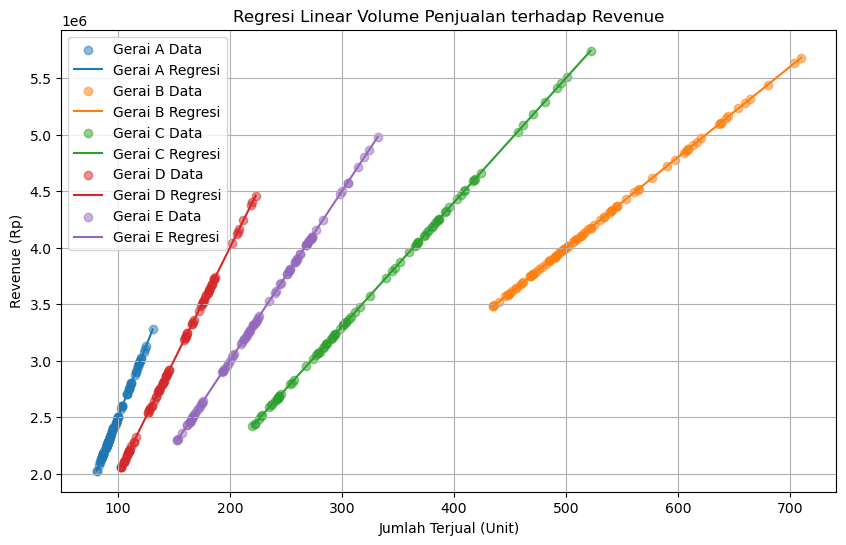

In [31]:
plt.figure(figsize=(10, 6))

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]
    
    x = data["Jumlah Terjual (Unit)"].values
    y = data["Pendapatan Kotor (Rp)"].values
    
    a, b = np.polyfit(x, y, 1)
    
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = a * x_line + b
    
    plt.scatter(x, y, alpha=0.5, label=f"{gerai} Data")
    plt.plot(x_line, y_line, label=f"{gerai} Regresi")

plt.xlabel("Jumlah Terjual (Unit)")
plt.ylabel("Revenue (Rp)")
plt.title("Regresi Linear Volume Penjualan terhadap Revenue")
plt.legend()
plt.grid(True)
plt.show()

- Analisis BEP
##### 5. Break-Even Point dengan Pencarian Akar

Break-Even Point (BEP) merupakan kondisi ketika pendapatan sama dengan total biaya sehingga balance bernilai nol.

Secara matematis:

Balance(X) = Revenue(X) - Variable Cost(X) - Fixed Cost

BEP diperoleh dengan mencari nilai X yang memenuhi:

Balance(X) = 0

Karena BEP merupakan permasalahan mencari akar suatu fungsi, metode pencarian akar dapat digunakan untuk menentukan volume penjualan yang menghasilkan kondisi balik modal.

Regresi Biaya Variabel

In [32]:
hasil_biaya = {}

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]
    
    x = data["Jumlah Terjual (Unit)"].values
    y = data["Biaya Variabel (Rp)"].values
    
    a, b = np.polyfit(x, y, 1)
    
    hasil_biaya[gerai] = {
        "a": a,
        "b": b
    }
    
    print(f"{gerai}:")
    print(f"Biaya Variabel = {a:.2f}X + {b:.2f}")
    print()

Gerai A:
Biaya Variabel = 8500.00X + 0.00

Gerai B:
Biaya Variabel = 4160.00X + 0.00

Gerai C:
Biaya Variabel = 4840.00X + 0.00

Gerai D:
Biaya Variabel = 7200.00X + -0.00

Gerai E:
Biaya Variabel = 6300.00X + 0.00



Membuat Fungsi Balance

In [33]:
def fungsi_balance(x, gerai):
    data_regresi = hasil_regresi[gerai]
    data_biaya = hasil_biaya[gerai]
    
    revenue = data_regresi["a"] * x + data_regresi["b"]
    biaya_variabel = data_biaya["a"] * x + data_biaya["b"]
    
    fixed_cost = df[df["Gerai"] == gerai]["Fixed Cost Harian (Rp)"].iloc[0]
    
    return revenue - biaya_variabel - fixed_cost

In [34]:
for gerai in gerai_list:
    print(gerai, fungsi_balance(100, gerai))

Gerai A -33333.0
Gerai B -349332.9999999997
Gerai C -1117333.0
Gerai D -1386666.0000000012
Gerai E 70000.00000000012


- Metode Bisection
##### 6. Pencarian Akar dengan Metode Bisection

Metode Bisection digunakan untuk mencari akar dari fungsi balance.

Metode ini bekerja dengan membagi interval menjadi dua bagian secara berulang. Interval yang dipilih harus memiliki perubahan tanda fungsi, yaitu:

f(a) × f(b) < 0

Iterasi dilakukan sampai nilai fungsi atau panjang interval mencapai toleransi yang telah ditentukan.

In [40]:
def bisection(f, a, b, tol=1e-6, max_iter=100):
    fa = f(a)
    fb = f(b)

    # Jika salah satu titik langsung merupakan akar
    if abs(fa) < tol:
        return a, 0

    if abs(fb) < tol:
        return b, 0

    # Syarat Bisection: harus ada perubahan tanda
    if fa * fb > 0:
        return None

    for i in range(max_iter):
        c = (a + b) / 2
        fc = f(c)

        if abs(fc) < tol or abs(b - a) < tol:
            return c, i + 1

        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

    return c, max_iter

Menentukan Interval BEP

In [ ]:
for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]

    xmin = data["Jumlah Terjual (Unit)"].min()
    xmax = data["Jumlah Terjual (Unit)"].max()

    print(f"{gerai}")
    print(f"Rentang data: {xmin} - {xmax}")
    print(f"Balance pada {xmin} unit: {fungsi_balance(xmin, gerai):,.2f}")
    print(f"Balance pada {xmax} unit: {fungsi_balance(xmax, gerai):,.2f}")
    print()

Gerai A
Rentang data: 81 - 131
Balance pada 81 unit: -346,833.00
Balance pada 131 unit: 478,167.00

Gerai B
Rentang data: 435 - 710
Balance pada 435 unit: 937,067.00
Balance pada 710 unit: 1,993,067.00

Gerai C
Rentang data: 220 - 522
Balance pada 220 unit: -378,133.00
Balance pada 522 unit: 1,482,187.00

Gerai D
Rentang data: 103 - 223
Balance pada 103 unit: -1,348,266.00
Balance pada 223 unit: 187,734.00

Gerai E
Rentang data: 153 - 332
Balance pada 153 unit: 531,100.00
Balance pada 332 unit: 2,088,400.00



Menghitung BEP

In [42]:
hasil_bep = []

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]

    # Titik awal pencarian
    a = 0

    # Mulai dari volume maksimum pada dataset
    b = data["Jumlah Terjual (Unit)"].max()

    # Jika belum ada perubahan tanda, perluas interval
    while fungsi_balance(a, gerai) * fungsi_balance(b, gerai) > 0:
        b = b * 2

        # Batas pengaman
        if b > 100000:
            break

    # Jalankan Bisection jika interval sudah memenuhi syarat
    hasil = bisection(
        lambda x: fungsi_balance(x, gerai),
        a,
        b
    )

    if hasil is not None:
        bep, iterasi = hasil

        hasil_bep.append([
            gerai,
            bep,
            iterasi,
            fungsi_balance(bep, gerai)
        ])
    else:
        hasil_bep.append([
            gerai,
            np.nan,
            np.nan,
            np.nan
        ])

bep_df = pd.DataFrame(
    hasil_bep,
    columns=[
        "Gerai",
        "BEP (Unit)",
        "Iterasi",
        "Balance pada BEP"
    ]
)

bep_df

,Gerai,BEP (Unit),Iterasi,Balance pada BEP
0,Gerai A,102.020182,28,0.006850
1,Gerai B,190.972135,31,-0.000824
2,Gerai C,281.385227,30,-0.000003
3,Gerai D,208.333281,29,-0.000278
4,Gerai E,91.954023,30,-0.002624


Membulatkan BEP

In [43]:
bep_df["BEP Dibulatkan (Unit)"] = np.ceil(bep_df["BEP (Unit)"])

bep_df

,Gerai,BEP (Unit),Iterasi,Balance pada BEP,BEP Dibulatkan (Unit)
0,Gerai A,102.020182,28,0.006850,103.0
1,Gerai B,190.972135,31,-0.000824,191.0
2,Gerai C,281.385227,30,-0.000003,282.0
3,Gerai D,208.333281,29,-0.000278,209.0
4,Gerai E,91.954023,30,-0.002624,92.0


Visualisasi BEP

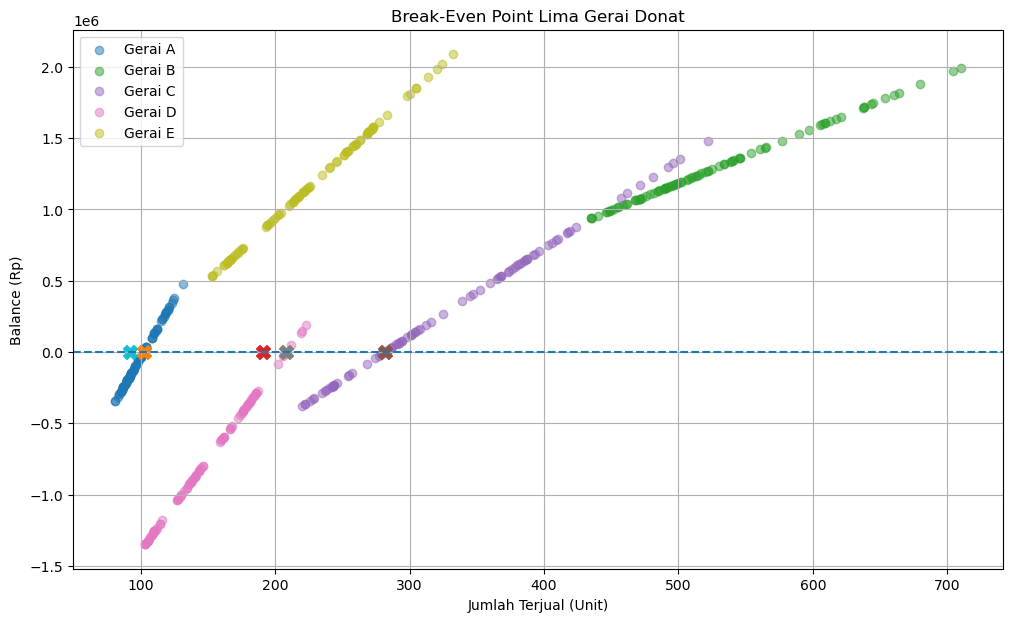

In [44]:
plt.figure(figsize=(12, 7))

for gerai in gerai_list:
    data = df[df["Gerai"] == gerai]
    
    x = data["Jumlah Terjual (Unit)"].values
    y = data["Balance (Rp)"].values
    
    plt.scatter(x, y, alpha=0.5, label=gerai)

    bep = bep_df.loc[
        bep_df["Gerai"] == gerai,
        "BEP (Unit)"
    ].values[0]
    
    if not np.isnan(bep):
        plt.scatter(
            bep,
            fungsi_balance(bep, gerai),
            s=100,
            marker="X"
        )

plt.axhline(0, linestyle="--")
plt.xlabel("Jumlah Terjual (Unit)")
plt.ylabel("Balance (Rp)")
plt.title("Break-Even Point Lima Gerai Donat")
plt.legend()
plt.grid(True)
plt.show()

Tabel Hasil Akhir

In [45]:
hasil_akhir = bep_df[
    ["Gerai", "BEP (Unit)", "BEP Dibulatkan (Unit)", "Iterasi"]
]

hasil_akhir

,Gerai,BEP (Unit),BEP Dibulatkan (Unit),Iterasi
0,Gerai A,102.020182,103.0,28
1,Gerai B,190.972135,191.0,31
2,Gerai C,281.385227,282.0,30
3,Gerai D,208.333281,209.0,29
4,Gerai E,91.954023,92.0,30


Interpretasi Tiap Gerai

- Interpretasi Tiap Gerai
##### 7. Interpretasi Hasil

##### Gerai A — Premium Gourmet

Gerai A memiliki harga jual yang relatif tinggi sehingga revenue meningkat cukup besar setiap terjadi peningkatan volume penjualan. Berdasarkan hasil pencarian akar, BEP tercapai pada volume penjualan sekitar ... unit per hari.

##### Gerai B — Mass Market Volume

Gerai B menggunakan harga jual yang lebih rendah sehingga membutuhkan volume penjualan yang lebih besar untuk mencapai kondisi BEP. Hasil perhitungan menunjukkan BEP sekitar ... unit per hari.

##### Gerai C — Promo Agresif

Gerai C memiliki strategi promosi yang menyebabkan harga jual per unit berada pada tingkat tertentu. Berdasarkan model regresi dan pencarian akar, BEP tercapai pada sekitar ... unit per hari.

##### Gerai D — Mall Premium Flagship

Gerai D memiliki fixed cost harian yang relatif tinggi karena biaya lokasi. Kondisi tersebut menyebabkan volume penjualan yang diperlukan untuk mencapai BEP menjadi lebih besar. Berdasarkan hasil perhitungan, BEP berada pada sekitar ... unit per hari.

##### Gerai E — Cloud Kitchen

Gerai E memiliki karakteristik biaya yang dipengaruhi oleh penggunaan platform delivery. Berdasarkan model dan pencarian akar, BEP diperoleh pada sekitar ... unit per hari.

##### 8. Kesimpulan

Berdasarkan hasil analisis, hubungan antara jumlah penjualan dan revenue pada kelima gerai dapat direpresentasikan menggunakan regresi linear. Peningkatan volume penjualan menyebabkan peningkatan revenue dengan pola yang sangat konsisten pada masing-masing gerai.

Selanjutnya, Break-Even Point ditentukan dengan mencari akar dari fungsi balance menggunakan metode Bisection. Fungsi balance dibentuk dari selisih antara revenue, biaya variabel, dan fixed cost.

Hasil BEP menunjukkan bahwa setiap gerai memiliki kebutuhan volume penjualan yang berbeda untuk mencapai kondisi balik modal. Perbedaan tersebut berkaitan dengan harga jual, biaya variabel, dan fixed cost dari masing-masing strategi gerai.

Dengan demikian, regresi digunakan untuk memodelkan hubungan antara volume penjualan dan revenue, sedangkan metode pencarian akar digunakan untuk menentukan volume penjualan ketika balance bernilai nol.